# NLP: tokenisation, normalisation and bag of words — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D011_C1_Intro_to_NLP.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# C1: Introduction to Natural Language Processing (NLP)

## 1. What is NLP?

**Natural Language Processing (NLP)** is a subfield of artificial intelligence (AI) that focuses on the interaction between computers and humans through natural language. The ultimate goal of NLP is to enable computers to understand, interpret, and generate human language in a way that is valuable.

### Why is it important?

NLP allows us to unlock insights from unstructured text data, which accounts for a vast majority of data generated today (emails, social media, reviews, documents).

### Common Applications:
- **Sentiment Analysis**: Determining if a review is positive or negative.
- **Chatbots**: Automated customer support agents.
- **Machine Translation**: Google Translate.
- **Text Summarization**: Generating concise summaries of long articles.
- **Spam Detection**: Filtering junk emails.

## 2. The NLP Pipeline

Processing text is not a single step but a pipeline of transformations. Raw text is messy and needs to be cleaned and structured before a machine learning model can understand it.

### Diagram: The Standard NLP Pipeline

The generic workflow for an NLP project typically looks like this:

![NLP Pipeline](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Falvinntnu.github.io%2Fpython-notes%2F_images%2Fnlp-pipeline.png&f=1&nofb=1&ipt=b62e9ffc1023a5c1ea78c2e07612206822549835705d2064e6cd53bd9a4e4dbc)

1.  **Raw Text**: The input data (e.g., "I love this product!!!").
2.  **Cleaning**: Removing noise like HTML tags, special characters (`!!!`), and converting to lowercase.
3.  **Tokenization**: Splitting text into individual words or sentences.
4.  **Stop Words Removal**: Removing common words like "is", "the", "and" that add little meaning.
5.  **Normalization**: Converting words to their root form (Stemming/Lemmatization).
6.  **Feature Extraction**: Converting text to numbers (Bag of Words, TF-IDF, Word Embeddings).
7.  **Modeling**: Training a Machine Learning model.

In [ ]:
# ═══ CHECKPOINT — "Setup and Libraries" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

pass

print("Checkpoint restored. Ready for: Setup and Libraries")

## 3. Setup and Libraries

We will use two of the most popular NLP libraries in Python:
1.  **NLTK (Natural Language Toolkit)**: Great for teaching, research, and understanding the basics.
2.  **spaCy**: Industrial-strength NLP, fast and efficient for production.

Let's install and import them.

In [ ]:
# !pip install nltk spacy pandas matplotlib wordcloud
# !python -m spacy download en_core_web_sm

  Using cached smart_open-7.5.0-py3-none-any.whl.metadata (24 kB)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/5.7 MB ? eta -:--:--


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/5.7 MB ? eta -:--:--


   ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/5.7 MB ? eta -:--:--


   ━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/5.7 MB 1.0 MB/s eta 0:00:06


   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.8/5.7 MB 981.7 kB/s eta 0:00:06

... (91 outputs left out)


     ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/12.8 MB 5.7 MB/s eta 0:00:03


     ━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━ 6.0/12.8 MB 21.4 MB/s eta 0:00:01


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.8 MB/s  0:00:00


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize

# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4') # Open Multilingual Wordnet

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/subashanannair/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/subashanannair/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/subashanannair/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/subashanannair/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 4. Concepts in Detail

### A. Tokenization

**Tokenization** is the process of breaking a stream of text up into words, phrases, symbols, or other meaningful elements called tokens.

**Why?** Computers cannot understand a paragraph as a whole; they need to analyze it word by word (or token by token).

In [ ]:
# TODO: compute `text`, `words`, `sentences`
# Hint: word_tokenize, sent_tokenize, nlp
# Name your result: text, words, sentences, doc

### B. Stop Words

**Stop words** are common words that are usually filtered out before processing natural language data (text) because they contain little lexical content.

*Examples*: 'the', 'is', 'at', 'which', 'on'.

**Note**: In some contexts (like machine translation or text generation), you might NOT want to remove them.

In [4]:
stop_words = set(stopwords.words('english'))

print(f"Total English stop words in NLTK: {len(stop_words)}")
print(f"Examples: {list(stop_words)[:10]}")

# Filtering example
filtered_words = [w for w in words if w.lower() not in stop_words]
print(f"\nOriginal: {words}")
print(f"Filtered: {filtered_words}")

Total English stop words in NLTK: 198
Examples: ['mightn', 'over', 'whom', 'its', "weren't", 'will', "i'd", 'while', 'm', 'itself']

Original: ['Hello', 'there', '!', 'NLP', 'is', 'amazing', '.', 'Is', "n't", 'it', '?']
Filtered: ['Hello', '!', 'NLP', 'amazing', '.', "n't", '?']


In [ ]:
# ═══ CHECKPOINT — "C. Normalization: Stemming vs. Lemmatization" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
nlp = spacy.load('en_core_web_sm')
text = "Hello there! NLP is amazing. Isn't it?"
words = word_tokenize(text)
sentences = sent_tokenize(text)
doc = nlp(text)
spacy_words = [token.text for token in doc]
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w.lower() not in stop_words]

print("Checkpoint restored. Ready for: C. Normalization: Stemming vs. Lemmatization")

### C. Normalization: Stemming vs. Lemmatization

Both techniques aim to reduce inflectional forms and sometimes derivationally related forms of a word to a common base form.

![Stemming vs Lemmatization](https://mermaid.ink/img/pako:eNp1kMtqwzAQRX9FzKpF_AGBrBxoA003XbQwSGPPWBpkSUZJIdh_r5Q8Am3d3DmPozujsyqMCqK4V7QWvsFK-MgdGof-7iuMH4eDxgHvmYKn9_QLNyVoz_jBRQPHo4H7R3hl8Mq5IN4Lbvgzxbv_h7_c_vpFGAruM94z6peKDrWCGvVRvbRWlFStWsHqVedsqdaUXLLygbKWQrKciqREk6JMs7RoyCrfv8m2ouxyKdskZTsVB5_JsSg5_EIeu5KHr-Rjl3LwM_k0pRz8IJ9dysFf8nlIOfgH_j6lPPsn_AOy43K1?type=png)

#### 1. Stemming
*   **Process**: Crude heuristic process that chops off the ends of words.
*   **Result**: The result might NOT be a valid word.
*   **Speed**: Faster.
*   **Example**: `Fishing`, `Fished`, `Fisher` -> `Fish`. `Argue`, `Argued` -> `Argu` (Not a real word).

#### 2. Lemmatization
*   **Process**: Uses vocabulary and morphological analysis of words.
*   **Result**: Returns the dictionary root word (Lemma).
*   **Speed**: Slower (needs to look up database).
*   **Example**: `Am`, `Is`, `Are` -> `Be`.

In [5]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words_to_test = ["running", "runs", "ran", "easily", "fairly", "better"]

print("{:<10} | {:<10} | {:<10}".format("Word", "Stem", "Lemma"))
print("-"*35)

for w in words_to_test:
    stem = stemmer.stem(w)
    # Note: lemmatizer defaults to noun (n), for verbs we need to specify pos='v'
    # We will just show the default behavior here for simplicity
    lemma = lemmatizer.lemmatize(w, pos='v') 
    print("{:<10} | {:<10} | {:<10}".format(w, stem, lemma))

Word       | Stem       | Lemma     
-----------------------------------


running    | run        | run       
runs       | run        | run       
ran        | ran        | run       
easily     | easili     | easily    
fairly     | fairli     | fairly    
better     | better     | better    


## 5. Practical Example: Product Reviews

Let's apply what we learned to real data. We have a file `data/NLP Product Reviews.csv`.

In [ ]:
# TODO: compute `df`
# Hint: pd.read_csv, df.head
# Name your result: df

### Creating a Clean Function

It is best practice to wrap your preprocessing steps into a function.

In [ ]:
# TODO: compute `text`, `doc`, `clean_tokens` from `Text`
# Hint: text.lower, nlp, .join(), clean_tokens.append, preprocess_text
# Name your result: text, doc, clean_tokens, sample_review

### Apply to the whole dataset

In [8]:
# This might take a few seconds
df['Cleaned_Text'] = df['Text'].astype(str).apply(preprocess_text)
df.head()

,Text,Cleaned_Text
0,I have bought several of the Vitality canned d...,buy vitality can dog food product find good qu...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived label jumbo salt peanut peanut...
2,This is a confection that has been around a fe...,confection century light pillowy citrus gelati...
3,If you are looking for the secret ingredient i...,look secret ingredient robitussin believe find...
4,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...


In [ ]:
# ═══ CHECKPOINT — "Visualization" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
nlp = spacy.load('en_core_web_sm')
text = "Hello there! NLP is amazing. Isn't it?"
words = word_tokenize(text)
sentences = sent_tokenize(text)
doc = nlp(text)
spacy_words = [token.text for token in doc]
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w.lower() not in stop_words]
from nltk.stem import PorterStemmer, WordNetLemmatizer
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
words_to_test = ['running', 'runs', 'ran', 'easily', 'fairly', 'better']
for w in words_to_test:
    stem = stemmer.stem(w)
    lemma = lemmatizer.lemmatize(w, pos='v')
    print('{:<10} | {:<10} | {:<10}'.format(w, stem, lemma))
df = pd.read_csv('../../00-data/NLP Product Reviews.csv')
def preprocess_text(text):
    """
    1. Lowercase
    2. Remove punctuation/numbers (keep only alphabets)
    3. Tokenize
    4. Remove stopwords
    5. Lemmatize
    """
    text = text.lower()
    doc = nlp(text)
    clean_tokens = []
    for token in doc:
        if token.is_alpha and (not token.is_stop):
            clean_tokens.append(token.lemma_)
    return ' '.join(clean_tokens)
sample_review = df['Text'].iloc[0]
df['Cleaned_Text'] = df['Text'].astype(str).apply(preprocess_text)

print("Checkpoint restored. Ready for: Visualization")

### Visualization

Let's see the most common words using a Word Cloud.

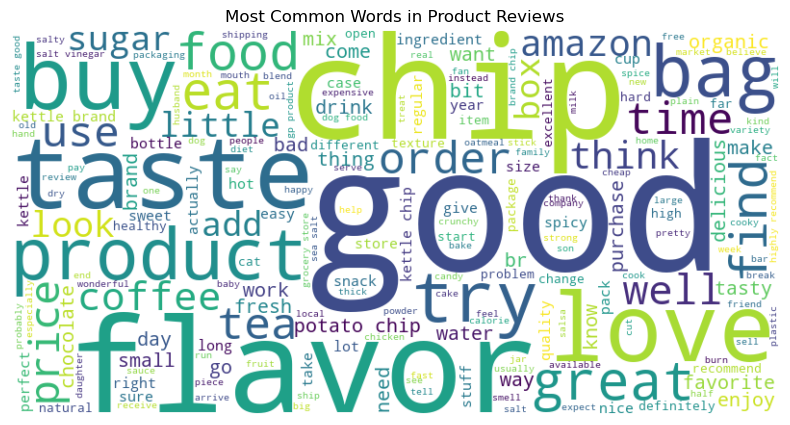

In [9]:
from wordcloud import WordCloud

all_text = " ".join(df['Cleaned_Text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Common Words in Product Reviews")
plt.show()

## 6. Exercises

Now it's your turn to practice!

### Exercise 1: Tokenization

Tokenize the following sentence into words using NLTK.

`sentence = "Natural Language Processing is fun and exciting!"`

In [10]:
# Your Code Here


### Exercise 2: Custom Cleaning

Create a function called `fast_clean` that only does two things:
1. Converts text to lowercase.
2. Removes stopwords.

Test it on: `"The quick brown fox jumps over the lazy dog."`

In [11]:
# Your Code Here


### Exercise 3: Named Entity Recognition (Bonus)

spaCy is excellent at finding "Entities" (names, dates, organizations). Run the code below and see what it finds.

`text_bonus = "Apple is looking at buying U.K. startup for $1 billion on Monday."`

In [ ]:
# TODO: compute `text_bonus`, `doc_bonus`
# Hint: nlp
# Name your result: text_bonus, doc_bonus